# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [4]:
import random 

class card:
    def __init__(self, suit, rank, value):
        self.suit = suit 
        self.rank = rank 
        self.value = value 
        
class deck:
    def __init__(self, number_decks):
        self.number_decks = number_decks
        self.cards = []

        self.create_deck()
        self.shuffle()
        self.add_plastic_card()

    # Create the deck constant, had to use the internet
    # to remind myself on the difference values 
    def create_deck(self):
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["2", "3", "4", "5", "6", "7", "8", "9",
             "10", "J", "Q", "K", "A"]

        # you want to loop through the suits and the ranks, and assign the value to each one
        for deck in range(self.number_decks):
            for suit in suits:
                for rank in ranks:
                    if rank in ["J", "Q", "K"]:
                        value = 10
                    elif rank == "A":
                        value = 11
                    else:
                        value = int(rank)

                    self.cards.append(card(suit, rank, value))

    def shuffle(self):
        random.shuffle(self.cards)

    def add_plastic_card(self):
        # We want to place the card in a random location so we can use random 
        plastic_card = card("Plastic", "Plastic", 0)

        postion_of_card = random.randint(0, len(self.cards))

        self.cards.insert(postion_of_card, plastic_card)

    # we want to draf a card from the top to start see what cards we are working with 
    def draw_card(self):
        return self.cards.pop(0)

In [5]:
test_deck = deck(2)

print(len(test_deck.cards))

105


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

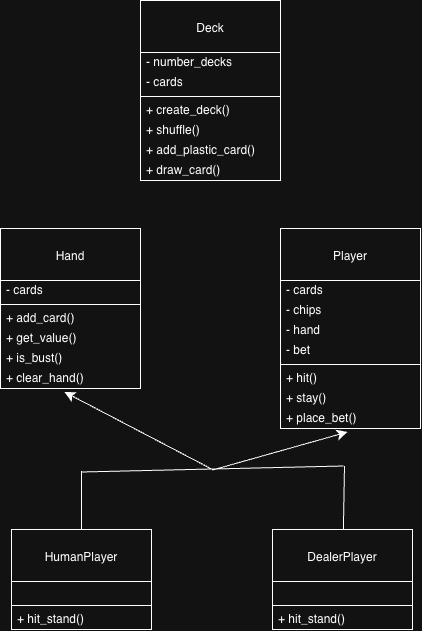

This is the inital UML Diagram, I will upload the ending one in the submission!

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

This is the class structure I want:

class card:
    [body of code]
class deck:
    [body of code]
class hand:
    [body of code]
class player:
    [body of code]
class HumanPlayer(player):
    [body of code]
class DealerPlayer(player):
    [body of code]
class Game:
    [body of code]

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [228]:
import random

class card:
    def __init__(self, suit, rank, value):
        self.suit = suit 
        self.rank = rank 
        self.value = value 
        

class deck:
    def __init__(self, number_decks):
        self.number_decks = number_decks
        self.cards = []
        self.reshuffle_needed = False
        self.reset_happened = False

        self.create_deck()
        self.shuffle()
        self.add_plastic_card()

    def create_deck(self):
        suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
        ranks = ["2", "3", "4", "5", "6", "7", "8", "9",
             "10", "J", "Q", "K", "A"]

        for deck in range(self.number_decks):
            for suit in suits:
                for rank in ranks:
                    if rank in ["J", "Q", "K"]:
                        value = 10
                    elif rank == "A":
                        value = 11
                    else:
                        value = int(rank)

                    self.cards.append(card(suit, rank, value))

    def shuffle(self):
        random.shuffle(self.cards)

    def add_plastic_card(self):
        plastic_card = card("Plastic", "Plastic", 0)

        position_of_card = random.randint(0, len(self.cards) - 1)

        self.cards.insert(position_of_card, plastic_card)

    def reset_deck(self):
        self.cards = []
        self.create_deck()
        self.shuffle()
        self.add_plastic_card()
        self.reshuffle_needed = False
        self.reset_happened = True

    def draw_card(self):

        if len(self.cards) == 0:
            self.reset_deck()

        drawn_card = self.cards.pop(0)

        if drawn_card.rank == "Plastic":
            self.reshuffle_needed = True

            if len(self.cards) == 0:
                self.reset_deck()

            drawn_card = self.cards.pop(0)

        return drawn_card


# the code above is from an earlier problem
class hand:
    def __init__(self):
        self.cards = []
        
    def add_card(self, new_card):
        self.cards.append(new_card)
    
    def get_value(self):
        total = 0
        aces = 0

        for card in self.cards:
            total += card.value

            if card.rank == "A":
                aces += 1

        # this ensures that if that hand goes over 21, then the added on valauye will be 1 instead
        # of 11 which the Ace originally is, just like in blackjack 
        while total > 21 and aces > 0:
            total -= 10
            aces -= 1

        return total
        
    def is_bust(self):
        return self.get_value() > 21
        
    def clear_hand(self):
        self.cards = [] 


class player:
    def __init__(self, name, chips):
        self.name = name
        self.chips = chips
        self.hand = hand()
        self.bet = 0

    def hit(self, game):
        game.draw_for_player(self)

    def stay(self):
        return

    def place_bet(self, amount):
        if amount > self.chips:
            raise ValueError("Need to input more chips.")

        self.bet = amount
        self.chips -= amount


class DealerPlayer(player):
    def __init__(self, name, chips):
        super().__init__(name, chips)

    def hit_stand(self, game):
        while self.hand.get_value() < 17:
            self.hit(game)

        return
        

class HumanPlayer(player):
    def __init__(self, name, chips):
        super().__init__(name, chips)

    def hit_stand(self, game):
        while True:
            print("Your hand value:", self.hand.get_value())

            choice = input("Hit or stand? ")

            if choice.lower() == "hit":
                self.hit(game)

                if self.hand.is_bust():
                    print("Bust!")
                    break

            elif choice.lower() == "stand":
                break

            else:
                print("Please enter hit or stand")


class NewStrategy(player):
    def __init__(self, name, chips, threshold = 0):
        super().__init__(name, chips)

        self.running_count = 0
        self.threshold = threshold

    def new_assignments_to_cards(self, shown_card):
        if shown_card.rank in ["2", "3", "4", "5", "6"]:
            return 1

        elif shown_card.rank in ["7", "8", "9"]:
            return 0

        else:
            return -1

    def captue_card_sum(self, shown_card):
        self.running_count += self.new_assignments_to_cards(shown_card)

    # New strat codeing 
    def hit_stand(self, game):
        while not self.hand.is_bust():

            if self.running_count < self.threshold:
                self.hit(game)

            else:
                break

    def reset_count(self):
        self.running_count = 0


class Game:
    def __init__(self, game_deck, players, dealer):
        self.deck = game_deck
        self.players = players
        self.dealer = dealer

    def update_counts(self, shown_card):
        for player in self.players:
            if isinstance(player, NewStrategy):
                player.captue_card_sum(shown_card)

    def reset_counts(self):
        for player in self.players:
            if isinstance(player, NewStrategy):
                player.reset_count()

    def draw_for_player(self, player):
        new_card = self.deck.draw_card()

        if self.deck.reset_happened:
            self.reset_counts()
            self.deck.reset_happened = False

        player.hand.add_card(new_card)

        self.update_counts(new_card)

    def deal_cards(self):
        # I used a wiki to review how to play blackjack again more in depbth
        # Youw ant to start with clearing the deck so you can pull new cards 
        for player in self.players:
            player.hand.clear_hand()

        self.dealer.hand.clear_hand()

        if self.deck.reshuffle_needed:
            self.deck.reset_deck()
            self.reset_counts()
            self.deck.reset_happened = False

        # you want to thend draw two random cards from the deck 
        for i in range(2):
            for player in self.players:
                self.draw_for_player(player)

            self.draw_for_player(self.dealer)

    def resolve_bet(self, player):
        result = self.determine_winner(player)

        if result == "Player Wins":
            player.chips += player.bet * 2

        elif result == "Tie":
            player.chips += player.bet

        player.bet = 0


    def play_round(self, bet_amount = 10, verbose = True):
    
        # Each player places the same bet
        for player in self.players:
            if player.chips >= bet_amount:
                player.place_bet(bet_amount)
    
        self.deal_cards()
    
        if verbose:
            print("Dealer starting value:", self.dealer.hand.get_value())
    
        # start with the plyer 
        for player in self.players:
            player.hit_stand(self)
    
        # then the dealer 
        self.dealer.hit_stand(self)
    
        # shows the dealers hand to work with 
        if verbose:
            print("Dealer value:", self.dealer.hand.get_value())
    
        # then the players valye is shown
        for player in self.players:
    
            if verbose:
                print(player.name, "value:", player.hand.get_value())
    
                if isinstance(player, NewStrategy):
                    print("Running count:", player.running_count)
    
                print(self.determine_winner(player))
    
            self.resolve_bet(player)


# now for the win conditions, you can either win if they go over 21, or a number
# is higher than the other number , otherwise it is a draw 

    def determine_winner(self, player):
        player_value = player.hand.get_value()
        dealer_value = self.dealer.hand.get_value()

        if player.hand.is_bust():
            return "Dealer Wins"

        elif self.dealer.hand.is_bust():
            return "Player Wins"

        elif player_value > dealer_value:
            return "Player Wins"

        elif player_value < dealer_value:
            return "Dealer Wins"

        else:
            return "Tie"

During testing, I kept having indent errors, and due to urgency, I decided to resolve the issues with AI. I asked ChatGPT to take my completed, straight-forward code, and fix the synatx and the indents, and I put that version in; i also told it to make sure it doesnt remove my comments, because i noticed that the output tends to remove human comments. I made this a pracatice after each implentation because i find that to be a very helpful debugging tool. 

5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [232]:
# We want to initalizr the bets and the deck 

game_deck = deck(4)

player1 = DealerPlayer("Player 1", 100)
player2 = DealerPlayer("Player 2", 100)
player3 = DealerPlayer("Player 3", 100)

dealer = DealerPlayer("Dealer", 100)

players = [player1, player2, player3]

game = Game(game_deck, players, dealer)

In [234]:
for i in range(3):
    print("Round", i + 1)

    game.play_round()

    print("--------------------")

Round 1
Dealer starting value: 13
Dealer value: 23
Player 1 value: 19
Player Wins
Player 2 value: 23
Dealer Wins
Player 3 value: 20
Player Wins
--------------------
Round 2
Dealer starting value: 17
Dealer value: 17
Player 1 value: 17
Tie
Player 2 value: 23
Dealer Wins
Player 3 value: 17
Tie
--------------------
Round 3
Dealer starting value: 14
Dealer value: 25
Player 1 value: 20
Player Wins
Player 2 value: 22
Dealer Wins
Player 3 value: 17
Player Wins
--------------------


In [280]:
human_test_deck = deck(2)
human = HumanPlayer("Human Player", 100)
dealer = DealerPlayer("Dealer", 100)

human_game = Game(human_test_deck, [human], dealer)

human_game.play_round()

Dealer starting value: 13
Your hand value: 16


Hit or stand?  hit


Your hand value: 18


Hit or stand?  stand


Dealer value: 23
Human Player value: 18
Player Wins


6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [238]:
class NewStrategy(player):
    def __init__(self, name, chips, threshold = 0):
        super().__init__(name, chips)

        self.running_count = 0
        self.threshold = threshold

    def new_assignments_to_cards(self, shown_card):
        if shown_card.rank in ["2", "3", "4", "5", "6"]:
            return 1
    
        elif shown_card.rank in ["7", "8", "9"]:
            return 0
    
        else:
            return -1

    def captue_card_sum(self, shown_card):
        self.running_count += self.new_assignments_to_cards(shown_card)

    # New strat codeing 
    def hit_stand(self, game):
        while not self.hand.is_bust():
            if self.running_count < self.threshold:
                self.hit(game)
            else:
                break

    def reset_count(self):
        self.running_count = 0

# hte coding up to this point, was not hard, but now that these changes were made, I was running into
# errors as it lead to some failture in output, so I decided to ask ChaatGPT what was goin gon
# I asked it: Here is my code, here is thr prompt [gave it the prompt]. What do I need to add
# to make this work. 

# What it told me was to add helper functions and update the code in the obove code to accomate the 
# changes for the new stragegy.

# What I had to change/learned: I had to add helper funcitons to mediate the new stragety. 
# Now that every tume anybody recieves a card, the Game sends that card to the strategy 
# player's count . The Game now takes control of the card drawing so it can keep track of the 
# cards that are seen. These are the little things that I failed to account for. 

In [240]:
strategy_deck = deck(4)

strategy = NewStrategy("Strategy Player", 100, 0)

player2 = DealerPlayer("Player 2", 100)
player3 = DealerPlayer("Player 3", 100)

dealer = DealerPlayer("Dealer", 100)

players = [strategy, player2, player3]

strategy_game = Game(strategy_deck, players, dealer)

for i in range(3):
    print("Round", i + 1)
    strategy_game.play_round()
    
    print("--------------------")


Round 1
Dealer starting value: 10
Dealer value: 20
Strategy Player value: 10
Running count: 2
Dealer Wins
Player 2 value: 18
Dealer Wins
Player 3 value: 21
Player Wins
--------------------
Round 2
Dealer starting value: 17
Dealer value: 17
Strategy Player value: 13
Running count: 1
Dealer Wins
Player 2 value: 18
Player Wins
Player 3 value: 19
Player Wins
--------------------
Round 3
Dealer starting value: 15
Dealer value: 25
Strategy Player value: 29
Running count: -5
Dealer Wins
Player 2 value: 18
Player Wins
Player 3 value: 18
Player Wins
--------------------


7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [243]:
# I did not know what verbose/quiet mode meant, so I did some reasearch. Then I learned I did not 
# know how to implement it. So I went into the GPT and asked it what I needed to do and had
# it guide me on how to od it. 

# What it told me. It told me i needed to add a fiundamental thing to my game logic, which was the 
# bet payouts, as in this part of the question, I had to record the players's winning
# Then the other part of the code, which I party did myself, was the testing code. 

starting_chips = 100
bet_amount = 10

game_deck = deck(6)

strategy_player = NewStrategy("Strategy Player", starting_chips, 0)

player1 = DealerPlayer("Player 1", starting_chips)
player2 = DealerPlayer("Player 2", starting_chips)
player3 = DealerPlayer("Player 3", starting_chips)

dealer = DealerPlayer("Dealer", starting_chips)

players = [strategy_player,player1,player2,player3]

game = Game(game_deck, players, dealer)

players = [ strategy_player,player1,player2,player3]

game = Game(game_deck, players, dealer)

In [245]:
# 50 test loop, withouht all the outputs 

rounds_played = 0

for i in range(50):

    if strategy_player.chips < bet_amount:
        print("Strategy Player is out of money.")
        break

    game.play_round(bet_amount, verbose = False)

    rounds_played += 1

Strategy Player is out of money.


In [247]:
# This part is the new part that chat GPT intoduced to me, that I glossed over. 
# I forgot to implente the funding the winnings in the end 
winnings = strategy_player.chips - starting_chips

print("Rounds played:", rounds_played)
print("Starting chips:", starting_chips)
print("Final chips:", strategy_player.chips)
print("Strategy Player winnings:", winnings)

Rounds played: 20
Starting chips: 100
Final chips: 0
Strategy Player winnings: -100


8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


In [254]:
import numpy as np
import matplotlib.pyplot as plt

all_winnings = []

starting_chips = 100
bet_amount = 10


for game_number in range(100):

    game_deck = deck(6)

    strategy_player = NewStrategy("Strategy Player", starting_chips, 0)

    player1 = DealerPlayer("Player 1", starting_chips)
    player2 = DealerPlayer("Player 2", starting_chips)
    player3 = DealerPlayer("Player 3", starting_chips)

    dealer = DealerPlayer("Dealer", starting_chips)

    players = [strategy_player,player1,player2, player3]

    game = Game(game_deck, players, dealer)

    for round_number in range(50):

        if strategy_player.chips < bet_amount:
            break

        game.play_round(bet_amount, verbose = False)

    winnings = strategy_player.chips - starting_chips

    all_winnings.append(winnings)

average_winnings = np.mean(all_winnings)
standard_deviation = np.std(all_winnings)

average_per_round = average_winnings / 50


wins = 0
losses = 0


for result in all_winnings:

    if result > 0:
        wins += 1

    elif result < 0:
        losses += 1


probability_win = wins / len(all_winnings)
probability_loss = losses / len(all_winnings)

Average winnings: -99.7
Average winnings per round: -1.994
Standard Deviation: 2.98496231131986
Probability of net winning: 0.0
Probability of net losing: 1.0


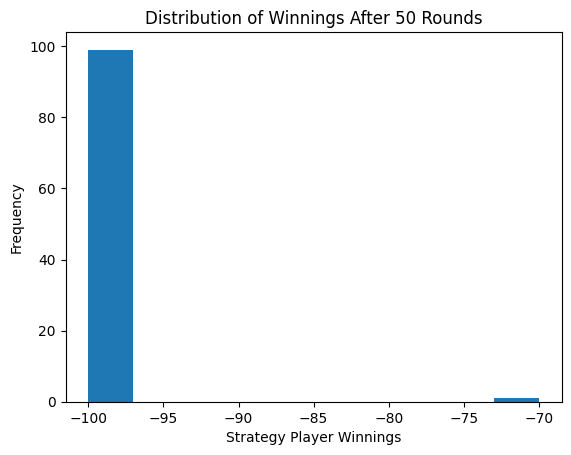

In [256]:
print("Average winnings:", average_winnings)
print("Average winnings per round:", average_per_round)
print("Standard Deviation:", standard_deviation)
print("Probability of net winning:", probability_win)
print("Probability of net losing:", probability_loss)

plt.hist(all_winnings, bins = 10)

plt.xlabel("Strategy Player Winnings")
plt.ylabel("Frequency")
plt.title("Distribution of Winnings After 50 Rounds")

plt.show()

9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

In [292]:
# We need to create teh test threshold values 
threshold_test = [-4, -2, 0, 2, 4]
threshold_results = []

starting_chips = 100
bet_amount = 10

for threshold in threshold_test:
    total_winnings = []

    for game_number in range(100):
    
        game_deck = deck(6)
    
        strategy_player = NewStrategy("Strategy Player", starting_chips, threshold)
    
        player1 = DealerPlayer("Player 1", starting_chips)
        player2 = DealerPlayer("Player 2", starting_chips)
        player3 = DealerPlayer("Player 3", starting_chips)
    
        dealer = DealerPlayer("Dealer", starting_chips)
    
        players = [strategy_player, player1, player2, player3]
    
        game = Game(game_deck, players, dealer)
    
        for round_number in range(50):
    
            if strategy_player.chips < bet_amount:
                break
    
            game.play_round(bet_amount, verbose = False)
    
        winnings = strategy_player.chips - starting_chips
    
        total_winnings.append(winnings)
    
    average_winnings = np.mean(total_winnings)
    standard_deviation = np.std(total_winnings)
    
    average_per_round = average_winnings / 50

    threshold_results.append(average_winnings)
    
    print(f"Threshold: {threshold}")
    print(f"Avg Winning: {average_winnings}")
    print(f"Average per round: {average_per_round}")
    print(f"Standard deviation: {standard_deviation}")
    print()

Threshold: -4
Avg Winning: -91.3
Average per round: -1.8259999999999998
Standard deviation: 26.894423213744524

Threshold: -2
Avg Winning: -96.3
Average per round: -1.926
Standard deviation: 14.467549896233294

Threshold: 0
Avg Winning: -100.0
Average per round: -2.0
Standard deviation: 0.0

Threshold: 2
Avg Winning: -99.5
Average per round: -1.99
Standard deviation: 4.9749371855331

Threshold: 4
Avg Winning: -100.0
Average per round: -2.0
Standard deviation: 0.0



In [355]:
best_winnings = max(threshold_results)

best_index = threshold_results.index(best_winnings)

best_threshold = threshold_test[best_index]

print("Best threshold:", best_threshold)
print("Best avg. winnings:", best_winnings)

Best threshold: -4
Best avg. winnings: -91.3


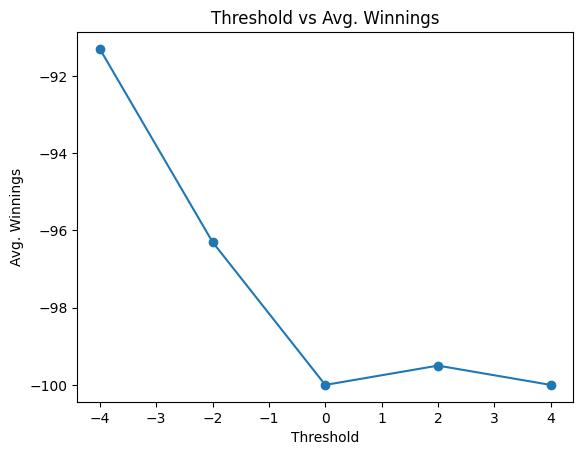

In [357]:
plt.plot(threshold_test, threshold_results, marker = "o")

plt.xlabel("Threshold")
plt.ylabel("Avg. Winnings")
plt.title("Threshold vs Avg. Winnings")

plt.show()

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

In [329]:
# I want to implement the strategy that I used myself when I got gambling. 

# I keep it simple, for example, I always hit when the hand is below 12
# in cases of 17 or higher, i usually stand
# and between 12 to 16, espically 16, I only hit if the dealers hand is atleast lower than 2 point
# than mine

class SudeepStrat(player):
    def __init__(self, name, chips):
        super().__init__(name, chips)

    def hit_stand(self, game):
        while not self.hand.is_bust():
            hand_value = self.hand.get_value()
            dealer_value = game.dealer.hand.get_value()

            # Now to implenet the ifs that make this possible 
            if hand_value < 12:
                self.hit(game)

            elif hand_value >= 17:
                break

            elif hand_value - dealer_value >= 2:
                self.hit(game)

            else:
                break

In [370]:
# This code is meant to teest the difference bwteen te old stratngrhy and the old one
# I think i need a new strategy
my_strategy_winnings = []

starting_chips = 100
bet_amount = 10

for game_number in range(100):

    game_deck = deck(6)

    strategy_player = SudeepStrat("My Strategy", starting_chips)

    player1 = DealerPlayer("Player 1", starting_chips)
    player2 = DealerPlayer("Player 2", starting_chips)
    player3 = DealerPlayer("Player 3", starting_chips)

    dealer = DealerPlayer("Dealer", starting_chips)

    players = [strategy_player, player1, player2, player3]

    game = Game(game_deck, players, dealer)

    for round_number in range(50):

        if strategy_player.chips < bet_amount:
            break

        game.play_round(bet_amount, verbose = False)

    winnings = strategy_player.chips - starting_chips
    my_strategy_winnings.append(winnings)

my_strategy_average = np.mean(my_strategy_winnings)

print("My strategy average winnings:", my_strategy_average)
print("Old strategy average winnings:", best_winnings)

difference = my_strategy_average - best_winnings

print("Difference:", difference)

My strategy average winnings: -57.5
Old strategy average winnings: -91.3
Difference: 33.8


In [371]:
game.play_round(bet_amount, verbose = True)

Dealer starting value: 20
Dealer value: 20
My Strategy value: 21
Player Wins
Player 1 value: 26
Dealer Wins
Player 2 value: 18
Dealer Wins
Player 3 value: 18
Dealer Wins
